## **Trabajo Práctico Final: Bank Subscription — Parte 3: Machine Learning**
____
__Universidad Tecnológica Nacional, Buenos Aires__\
__Ingeniería Industrial__\
__Cátedra de Ciencia de Datos - ClusterAI 2026__
____
Grupo 3: Galdames, González, Molina, Resines.
- Nombre: **María**
- Apellido: **González**
- Legajo: **259571-0**
____

**Objetivo:** predecir la variable `subscription` (1 = el cliente se suscribe a la campaña).

Plan del notebook:
1. Pipeline de scikit-learn: preprocesamiento (imputación + escalado + dummies) + modelo.
2. Modelos vistos en clase: **Regresión Logística, KNN, Árbol de Decisión, Random Forest, XGBoost y Red Neuronal (MLP)**, con búsqueda de hiper-parámetros (`GridSearchCV`) y **validación cruzada de 5 folds**, optimizando el **AUC-ROC**.
3. Evaluación en el set de test: matriz de confusión, accuracy, sensibilidad, especificidad y AUC-ROC.
4. **Umbral de decisión según los costos** de la campaña (clase 05).
5. **Reducción de dimensionalidad con PCA** y re-entrenamiento de los modelos.
6. Escenario realista **sin `duration`** (variable que solo se conoce después de la llamada).

> Requiere haber ejecutado antes `clusterai_maria_gonzalez_preprocesamiento.ipynb` (genera `datos/bank_train.csv` y `datos/bank_test.csv`).

# Marco teórico
**Aprendizaje supervisado — clasificación binaria (clases 03 y 04).** Disponemos de un dataset $S = \{(x_i, y_i)\}$ de muestras $x_i \in \mathbb{R}^d$ (cada cliente descripto por $d$ features) y etiquetas $y_i \in \{0, 1\}$ (`subscription`). Suponemos que existe una función objetivo desconocida $f(x) = y$ (*ground truth*) y buscamos, dentro de un espacio de hipótesis $H$, una función $f'(x)$ caracterizada por **parámetros** $w$ que minimice una **función de costo** $L(y, y')$ sobre las muestras de entrenamiento y que **generalice** a muestras nunca vistas.

**Parámetros vs hiper-parámetros.** Los parámetros ($w$) los aprende el algoritmo en `.fit()`; los hiper-parámetros (C, K, `max_depth`, ...) los fija el usuario y definen la complejidad del modelo. Se eligen por **validación cruzada (K-fold) + búsqueda de grilla (Grid Search)** usando **solo el set de train**.

**Sesgo vs varianza.** Un modelo muy simple sub-ajusta (*underfitting*, alto sesgo); uno muy complejo sobre-ajusta (*overfitting*, alta varianza). La regularización y la validación cruzada buscan el punto intermedio.

**Pipeline de trabajo (clases 03, 04 y 07):**
1. Dividir train y test.
2. Cross-validation + Grid Search con `X_train`, `y_train`.
3. Seleccionar el mejor modelo e hiper-parámetros (por el resultado de CV, nunca por test).
4. Clasificar `X_test` sin mostrarle `y_test` al modelo.
5. Evaluar comparando `y_pred` vs `y_test`.

**Data leakage (clase 07).** Si el imputador, el scaler o el one-hot se ajustan con todo el dataset, información de validación/test se filtra al entrenamiento. Por eso todo el preprocesamiento va dentro de un `Pipeline` + `ColumnTransformer`, que en cada fold se re-ajusta solo con las K−1 particiones de entrenamiento.

**Métricas (clase 03).** A partir de la matriz de confusión (TP, TN, FP, FN):
- Accuracy $= \frac{TP+TN}{Total}$ — engañosa con clases desbalanceadas.
- Sensibilidad (recall) $= \frac{TP}{TP+FN}$ — qué proporción de los suscriptores detectamos.
- Especificidad $= \frac{TN}{TN+FP}$ — qué proporción de los no suscriptores descartamos correctamente.
- **AUC-ROC**: área bajo la curva ROC (TPR vs FPR al barrer todos los umbrales de clasificación). Cuanto más cerca de 0,5, más parecido a "tirar una moneda"; cuanto más cerca de 1, mejor el clasificador. Da una idea de la calidad del clasificador **independientemente del accuracy y del umbral**, por eso es la métrica con la que elegimos los modelos.

# Librerías

In [1]:
import os, time, warnings
import pandas as pd                      # dataframes
import numpy as np                       # cálculo numérico
import matplotlib.pyplot as plt          # gráficos
import seaborn as sns                    # gráficos estadísticos

# pre-procesamiento y workflow (clase 07)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV, cross_val_score, learning_curve
from sklearn.decomposition import PCA    # reducción de dimensionalidad (clase 09)

# modelos de clasificación
from sklearn.linear_model import LogisticRegression     # clase 04
from sklearn.neighbors import KNeighborsClassifier      # clase 03
from sklearn.tree import DecisionTreeClassifier         # clase 06
from sklearn.ensemble import RandomForestClassifier     # clase 06 (bagging)
from xgboost import XGBClassifier                       # clase 06 (boosting)
from sklearn.neural_network import MLPClassifier        # clase 10

# métricas (clase 03)
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings('ignore')
sns.set_context("talk", font_scale=0.7)
sns.set_style("ticks")
RANDOM_STATE = 42                        # semilla para reproducibilidad
CV = 5                                   # cantidad de folds de la validación cruzada
os.makedirs('figuras', exist_ok=True)
os.makedirs('resultados', exist_ok=True)

def guardar(nombre):
    # guarda la figura actual en la carpeta figuras/ para usarla en el reporte
    plt.savefig(f'figuras/{nombre}.png', dpi=150, bbox_inches='tight')

# Carga de los datos preprocesados

In [2]:
train = pd.read_csv('datos/bank_train.csv')
test = pd.read_csv('datos/bank_test.csv')
target = 'subscription'

X_train, y_train = train.drop(columns=target), train[target]   # features y etiquetas de train
X_test, y_test = test.drop(columns=target), test[target]       # features y etiquetas de test
print('Train:', X_train.shape, ' suscriptos: {:.2%}'.format(y_train.mean()))
print('Test: ', X_test.shape, ' suscriptos: {:.2%}'.format(y_test.mean()))

Train: (36168, 17)  suscriptos: 11.70%
Test:  (9043, 17)  suscriptos: 11.70%


# Pipeline de preprocesamiento
Mismo preprocesador definido en el notebook de preprocesamiento. Al ir dentro del `Pipeline`, en cada fold de la validación cruzada se ajusta solo con los datos de entrenamiento de ese fold.

In [3]:
num_cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous', 'contacto_previo']
cat_cols = ['job', 'marital', 'education', 'credit_default', 'housing_loan',
            'personal_loan', 'contact', 'month', 'poutcome']

def construir_preprocesador(num_cols, cat_cols):
    # numéricas: imputar con la mediana -> estandarizar
    num_pipe = Pipeline([('imputer', SimpleImputer(strategy='median')),
                         ('scaler', StandardScaler())])
    # categóricas: imputar con la moda -> dummies (one-hot)
    cat_pipe = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                         ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    # se aplican en paralelo y se concatenan
    return ColumnTransformer([('num', num_pipe, num_cols), ('cat', cat_pipe, cat_cols)])

# Funciones de evaluación

In [4]:
def metricas(y_true, proba, umbral=0.5):
    # calcula las métricas vistas en clase a partir de las probabilidades predichas
    pred = (proba >= umbral).astype(int)                       # clase predicha según el umbral
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()    # elementos de la matriz de confusión
    return {'accuracy': accuracy_score(y_true, pred),           # (TP+TN)/Total
            'sensibilidad': tp / (tp + fn),                     # TP/(TP+FN)
            'especificidad': tn / (tn + fp),                    # TN/(TN+FP)
            'auc_roc': roc_auc_score(y_true, proba)}            # área bajo la curva ROC

def matriz_confusion(y_true, proba, umbral, titulo, ax=None):
    # grafica la matriz de confusión para un umbral dado
    cm = confusion_matrix(y_true, (proba >= umbral).astype(int))
    ConfusionMatrixDisplay(cm, display_labels=['No suscribe', 'Suscribe']).plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)
    (ax or plt.gca()).set_title(titulo)

# Modelo de referencia (baseline)
Como indica el checklist de la clase 07, antes de entrenar modelos complejos conviene tener un **modelo simple de referencia**. El más simple posible es predecir siempre la clase mayoritaria ("nadie se suscribe"). Cualquier modelo útil debe superarlo.

In [5]:
proba_baseline = np.zeros(len(y_test))          # probabilidad 0 para todos: "nadie se suscribe"
pd.Series(metricas(y_test, proba_baseline)).round(3)

accuracy         0.883
sensibilidad     0.000
especificidad    1.000
auc_roc          0.500
dtype: float64

Con **88% de accuracy** y **0 de sensibilidad**, el baseline muestra por qué el accuracy es engañoso en este problema: no detecta a ningún cliente que suscribe. Su AUC de 0,5 equivale a "tirar una moneda".

# Modelos utilizados
**Regresión Logística (clase 04).** Clasificador **lineal**: una combinación lineal $w \cdot x + b$ seguida de la función **sigmoide** $\sigma(z) = 1/(1+e^{-z})$, que devuelve la probabilidad $P(y=1|x)$. Los pesos $w$ se aprenden minimizando la **cross-entropy** con descenso por gradiente. Hiper-parámetro `C`: inverso de la fuerza de **regularización L2** (Ridge), que penaliza pesos grandes para evitar el overfitting (C chico = más regularización).

**KNN (clase 03).** Modelo **basado en instancias** y *lazy learning*: para clasificar un cliente busca los K clientes de train más cercanos (distancia euclídea) y vota. Es **sensible a la escala** (por eso se estandariza), sufre la **maldición de la dimensionalidad** (después de las dummies tenemos ~50 dimensiones) y **se desbalancea si una clase es mucho más frecuente**. Hiper-parámetros: `n_neighbors` (K chico → overfitting, K grande → underfitting; valores impares para evitar empates) y `weights` (cada vecino pesa igual o según su distancia).

**Árbol de Decisión (clase 06).** Divide el espacio con preguntas sobre las variables (*Recursive Binary Splitting*). En cada nodo elige el corte que más reduce la **impureza** (índice de **Gini** o **entropía** → *information gain*). Es interpretable pero propenso al overfitting si no se limita (`max_depth`, `min_samples_leaf`).

**Random Forest (clase 06).** Ensamble por **bagging**: entrena muchos árboles en paralelo sobre muestras con reemplazo y con subconjuntos aleatorios de columnas, y vota. Promediar árboles **reduce la varianza** de un árbol individual.

**XGBoost (clase 06).** Ensamble por **boosting**: entrena árboles débiles de forma **secuencial**, donde cada árbol aproxima el gradiente negativo de la función de pérdida (corrige los errores del anterior), con pasos controlados por la tasa de aprendizaje (`learning_rate`).

**Red Neuronal — Perceptrón Multicapa (clase 10).** Capas ocultas de neuronas con activación **ReLU** y una salida **sigmoide**; los pesos se aprenden minimizando la **cross-entropy** mediante **backpropagation** y descenso por gradiente. Hiper-parámetros: arquitectura (`hidden_layer_sizes`) y `alpha` (**regularización L2** sobre los pesos).

# Entrenamiento con GridSearchCV
Para cada modelo se define una grilla de hiper-parámetros y se elige la combinación con mayor **AUC-ROC promedio en validación cruzada de 5 folds**. El set de test no se usa en esta etapa.

| Modelo | Hiper-parámetros explorados |
|---|---|
| Regresión Logística | `C` |
| KNN | `n_neighbors`, `weights` |
| Árbol de Decisión | `criterion`, `max_depth`, `min_samples_leaf` |
| Random Forest | `max_depth`, `min_samples_leaf` |
| XGBoost | `max_depth`, `learning_rate` |
| Red Neuronal MLP | `hidden_layer_sizes`, `alpha` |

In [6]:
modelos = {
    'Regresión Logística': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                            {'clf__C': [0.01, 0.1, 1, 10]}),
    'KNN': (KNeighborsClassifier(),
            {'clf__n_neighbors': [11, 31, 61],
             'clf__weights': ['uniform', 'distance']}),
    'Árbol de Decisión': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                          {'clf__criterion': ['gini', 'entropy'],
                           'clf__max_depth': [4, 6, 8, 12],
                           'clf__min_samples_leaf': [1, 20, 50]}),
    'Random Forest': (RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=1),
                      {'clf__max_depth': [12, None],
                       'clf__min_samples_leaf': [1, 5]}),
    'XGBoost': (XGBClassifier(n_estimators=300, subsample=0.8, colsample_bytree=0.8,
                              random_state=RANDOM_STATE, n_jobs=1),
                {'clf__max_depth': [3, 6],
                 'clf__learning_rate': [0.05, 0.1]}),
    'Red Neuronal (MLP)': (MLPClassifier(max_iter=200, random_state=RANDOM_STATE),
                           {'clf__hidden_layer_sizes': [(32,), (64, 32)],
                            'clf__alpha': [1e-4, 1e-2]}),
}

busquedas = {}      # guardamos cada GridSearchCV ajustado
for nombre, (clf, grilla) in modelos.items():
    pipe = Pipeline([('pre', construir_preprocesador(num_cols, cat_cols)), ('clf', clf)])   # preprocesamiento + modelo
    gs = GridSearchCV(pipe, grilla, cv=CV, scoring='roc_auc', n_jobs=-1)                  # grid search con CV de 5 folds
    t0 = time.time()
    gs.fit(X_train, y_train)                                                               # solo con train
    busquedas[nombre] = gs
    print(f'{nombre:22s} AUC CV = {gs.best_score_:.4f}  ({time.time() - t0:.0f} s)  mejores: {gs.best_params_}')

Regresión Logística    AUC CV = 0.8784  (21 s)  mejores: {'clf__C': 0.1}
KNN                    AUC CV = 0.8762  (24 s)  mejores: {'clf__n_neighbors': 61, 'clf__weights': 'distance'}
Árbol de Decisión      AUC CV = 0.8789  (46 s)  mejores: {'clf__criterion': 'entropy', 'clf__max_depth': 12, 'clf__min_samples_leaf': 50}
Random Forest          AUC CV = 0.9067  (117 s)  mejores: {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
XGBoost                AUC CV = 0.9176  (28 s)  mejores: {'clf__learning_rate': 0.05, 'clf__max_depth': 6}
Red Neuronal (MLP)     AUC CV = 0.8987  (339 s)  mejores: {'clf__alpha': 0.01, 'clf__hidden_layer_sizes': (32,)}


In [7]:
# resumen de validación cruzada: AUC medio y desvío entre folds del mejor modelo de cada grilla
cv_res = []
for nombre, gs in busquedas.items():
    i = gs.best_index_
    cv_res.append({'modelo': nombre,
                   'auc_cv_media': gs.cv_results_['mean_test_score'][i],
                   'auc_cv_std': gs.cv_results_['std_test_score'][i],
                   'mejores_hiperparametros': {k.replace('clf__', ''): v for k, v in gs.best_params_.items()}})
cv_res = pd.DataFrame(cv_res).sort_values('auc_cv_media', ascending=False)
cv_res.round(4)

,modelo,auc_cv_media,auc_cv_std,mejores_hiperparametros
4,XGBoost,0.9176,0.0032,"{'learning_rate': 0.05, 'max_depth': 6}"
3,Random Forest,0.9067,0.0026,"{'max_depth': None, 'min_samples_leaf': 5}"
5,Red Neuronal (MLP),0.8987,0.0030,"{'alpha': 0.01, 'hidden_layer_sizes': (32,)}"
2,Árbol de Decisión,0.8789,0.0066,"{'criterion': 'entropy', 'max_depth': 12, 'min..."
0,Regresión Logística,0.8784,0.0047,{'C': 0.1}
1,KNN,0.8762,0.0056,"{'n_neighbors': 61, 'weights': 'distance'}"


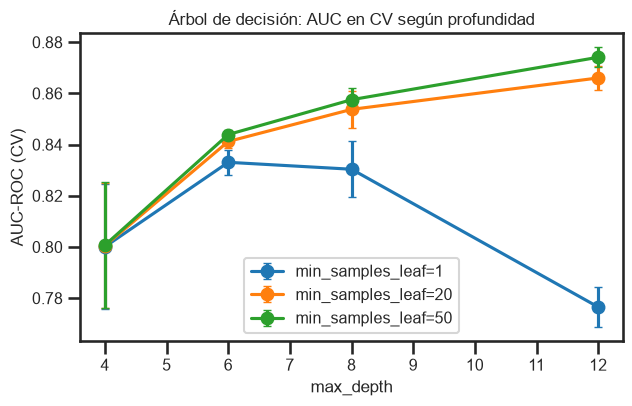

In [8]:
# cómo varía el AUC del árbol según la profundidad (sub-ajuste vs sobre-ajuste)
res_tree = pd.DataFrame(busquedas['Árbol de Decisión'].cv_results_)
res_tree = res_tree[res_tree.param_clf__criterion == 'gini']
fig, ax = plt.subplots(figsize=(7, 4))
for leaf, g in res_tree.groupby('param_clf__min_samples_leaf'):
    ax.errorbar(g.param_clf__max_depth, g.mean_test_score, yerr=g.std_test_score, marker='o', capsize=3, label=f'min_samples_leaf={leaf}')
ax.set_xlabel('max_depth'); ax.set_ylabel('AUC-ROC (CV)'); ax.legend()
ax.set_title('Árbol de decisión: AUC en CV según profundidad')
plt.show()

Con poca profundidad el árbol sub-ajusta (alto sesgo). Con mucha profundidad y hojas de 1 muestra, el AUC de validación cae porque el árbol memoriza el train (alta varianza). Exigir un mínimo de muestras por hoja (`min_samples_leaf`) funciona como regularización.

# Evaluación en el set de test (umbral 0,5)

In [9]:
probas = {}            # probabilidades predichas en test por cada modelo
resultados = []
for nombre, gs in busquedas.items():
    probas[nombre] = gs.predict_proba(X_test)[:, 1]          # probabilidad de suscribir
    resultados.append({'modelo': nombre, 'escenario': 'Original', **metricas(y_test, probas[nombre])})
res_test = pd.DataFrame(resultados).sort_values('auc_roc', ascending=False)
res_test.round(3)

,modelo,escenario,accuracy,sensibilidad,especificidad,auc_roc
4,XGBoost,Original,0.907,0.439,0.969,0.919
3,Random Forest,Original,0.901,0.304,0.980,0.912
5,Red Neuronal (MLP),Original,0.903,0.435,0.965,0.901
2,Árbol de Decisión,Original,0.900,0.408,0.965,0.888
0,Regresión Logística,Original,0.900,0.304,0.979,0.883
1,KNN,Original,0.896,0.214,0.987,0.876


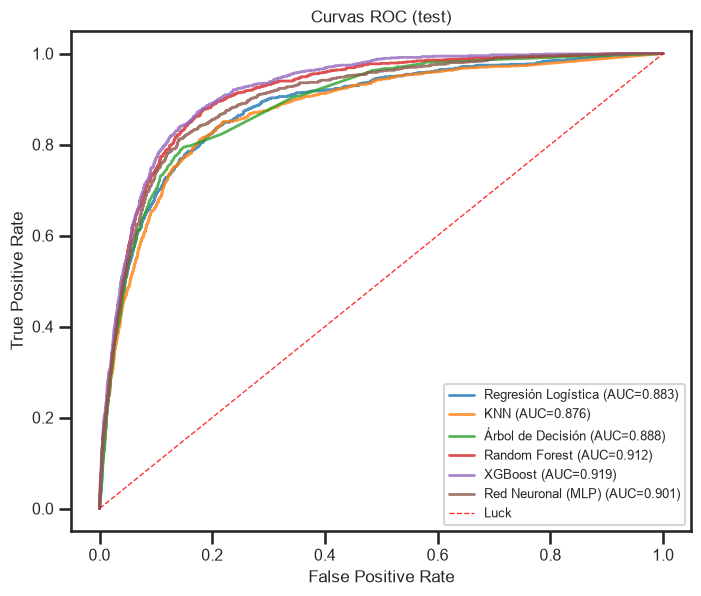

In [10]:
# curvas ROC de todos los modelos
plt.figure(figsize=(8, 6.5))
for nombre, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, alpha=0.8, label=f'{nombre} (AUC={roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', lw=1, color='r', label='Luck', alpha=.8)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.legend(loc='lower right', fontsize=9)
plt.title('Curvas ROC (test)')
guardar('ml_roc')
plt.show()

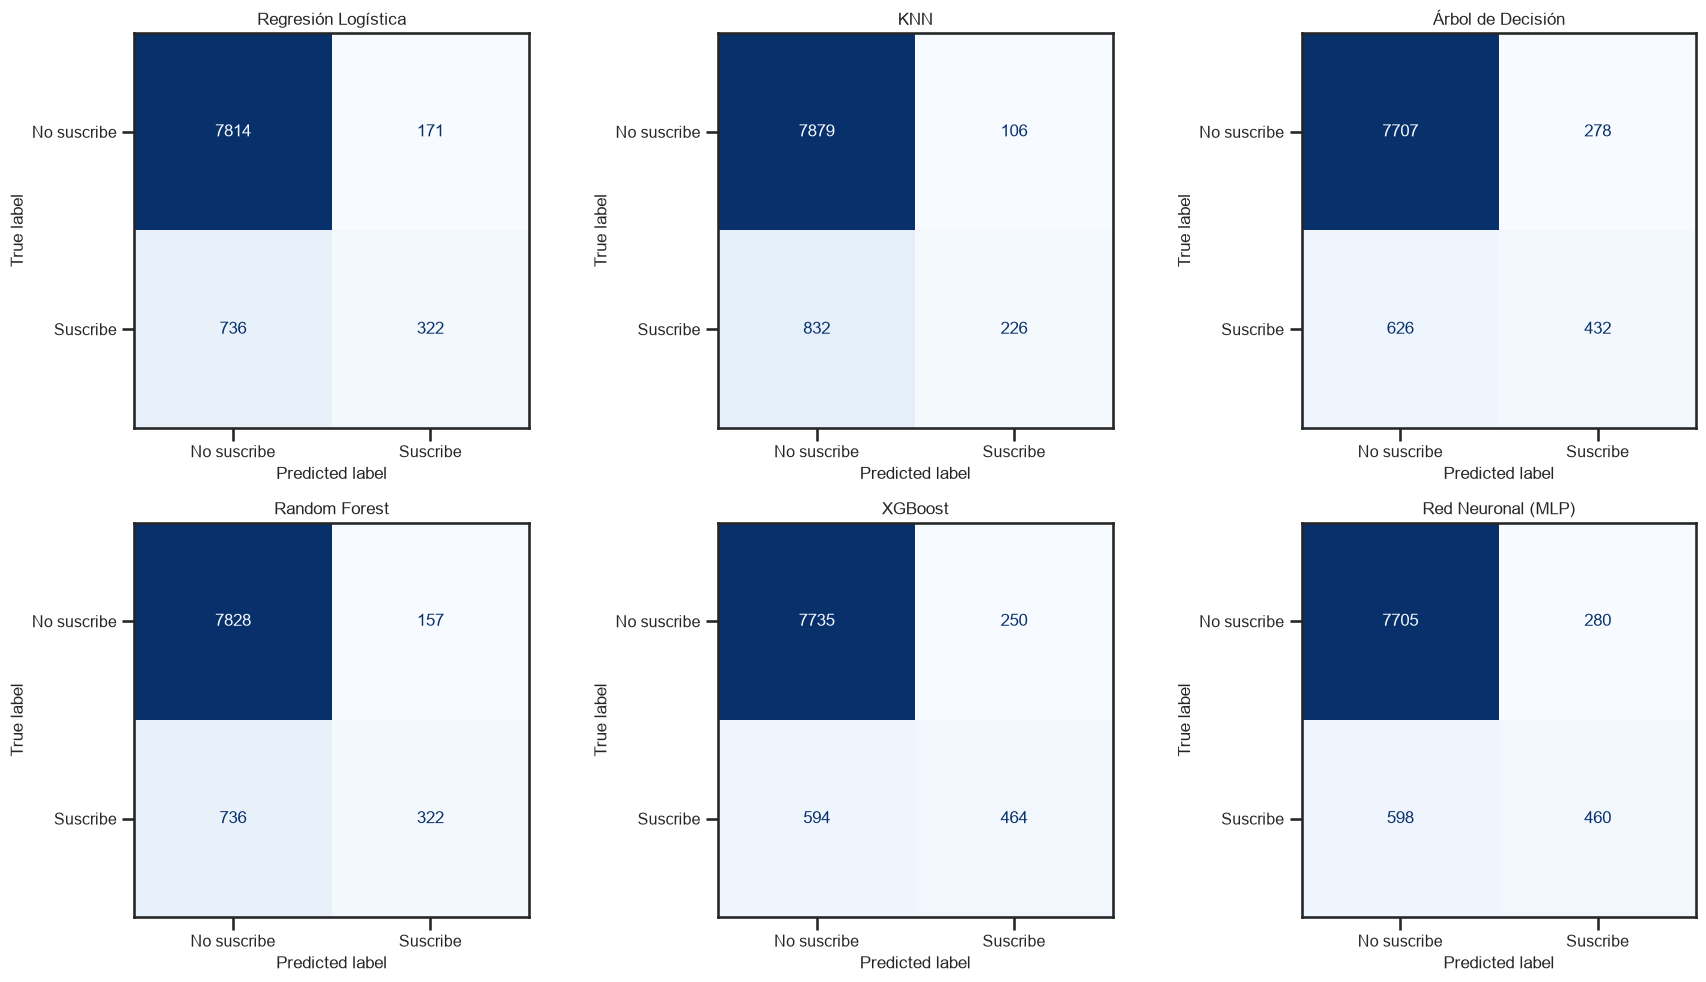

In [11]:
# matrices de confusión con umbral 0.5
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for ax, (nombre, p) in zip(axs.ravel(), probas.items()):
    matriz_confusion(y_test, p, 0.5, nombre, ax=ax)
plt.tight_layout()
guardar('ml_confusion_05')
plt.show()

Con el umbral por defecto de 0,5 se ve el efecto del **desbalance de clases**: todos los modelos tienen **especificidad muy alta** (descartan bien a los que no suscriben) pero **sensibilidad baja**, porque se les escapa una parte importante de los suscriptores. KNN es el caso extremo, tal como anticipa la teoría (se desbalancea cuando una clase es mucho más frecuente).

El AUC, que no depende del umbral, muestra que la capacidad de **ordenar** a los clientes según su probabilidad de suscribir es buena en todos los modelos. Lo que hay que ajustar según el objetivo del negocio es el **umbral de decisión** (ver más abajo).

# Modelo seleccionado
Elegimos el modelo con **mayor AUC en validación cruzada**, no en test, para que el test siga siendo una estimación honesta del desempeño en datos nuevos.

In [12]:
mejor_nombre = cv_res.iloc[0]['modelo']                 # el de mayor AUC en CV
mejor = busquedas[mejor_nombre].best_estimator_
p_mejor = probas[mejor_nombre]
print('Modelo seleccionado:', mejor_nombre)
print('Hiper-parámetros:', busquedas[mejor_nombre].best_params_)
pd.Series(metricas(y_test, p_mejor)).round(3)

Modelo seleccionado: XGBoost
Hiper-parámetros: {'clf__learning_rate': 0.05, 'clf__max_depth': 6}


accuracy         0.907
sensibilidad     0.439
especificidad    0.969
auc_roc          0.919
dtype: float64

## Curva de aprendizaje (clase 03)
Entrenamos el modelo seleccionado con cantidades crecientes de muestras de train y medimos el AUC en train y en validación (CV). Permite diagnosticar **sesgo vs varianza**: una brecha grande entre ambas curvas indica alta varianza (overfitting); dos curvas bajas y juntas indican alto sesgo (underfitting). Idealmente ambas curvas convergen a un valor.

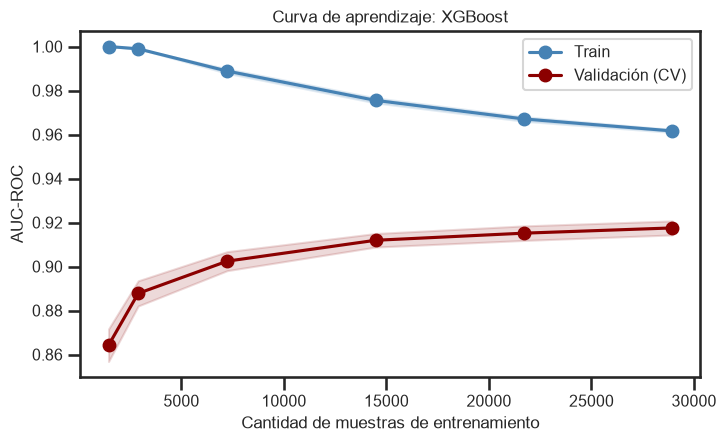

AUC train / validación con todo el train: 0.962 / 0.918


In [13]:
tam, sc_train, sc_val = learning_curve(mejor, X_train, y_train, cv=CV, scoring='roc_auc',
                                        train_sizes=[0.05, 0.1, 0.25, 0.5, 0.75, 1.0], n_jobs=-1)
fig, ax = plt.subplots(figsize=(8, 4.5))
for sc, lab, col in [(sc_train, 'Train', 'steelblue'), (sc_val, 'Validación (CV)', 'darkred')]:
    ax.plot(tam, sc.mean(axis=1), marker='o', color=col, label=lab)
    ax.fill_between(tam, sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), color=col, alpha=0.15)
ax.set_xlabel('Cantidad de muestras de entrenamiento'); ax.set_ylabel('AUC-ROC'); ax.legend()
ax.set_title(f'Curva de aprendizaje: {mejor_nombre}')
guardar('ml_learning_curve')
plt.show()
print('AUC train / validación con todo el train:', sc_train.mean(axis=1)[-1].round(3), '/', sc_val.mean(axis=1)[-1].round(3))

## Curva de entrenamiento de la red neuronal (clase 10)
Evolución de la función de costo (*cross-entropy*) en cada época del descenso por gradiente.

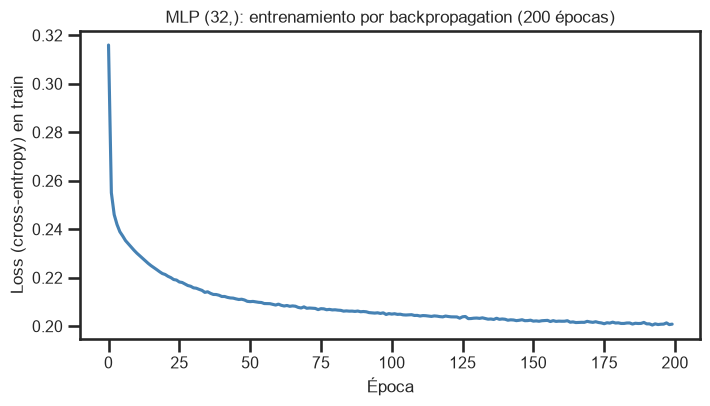

In [14]:
mlp = busquedas['Red Neuronal (MLP)'].best_estimator_.named_steps['clf']
plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_, color='steelblue')
plt.xlabel('Época'); plt.ylabel('Loss (cross-entropy) en train')
plt.title(f'MLP {mlp.hidden_layer_sizes}: entrenamiento por backpropagation ({mlp.n_iter_} épocas)')
guardar('ml_mlp_loss')
plt.show()

## Importancia de variables

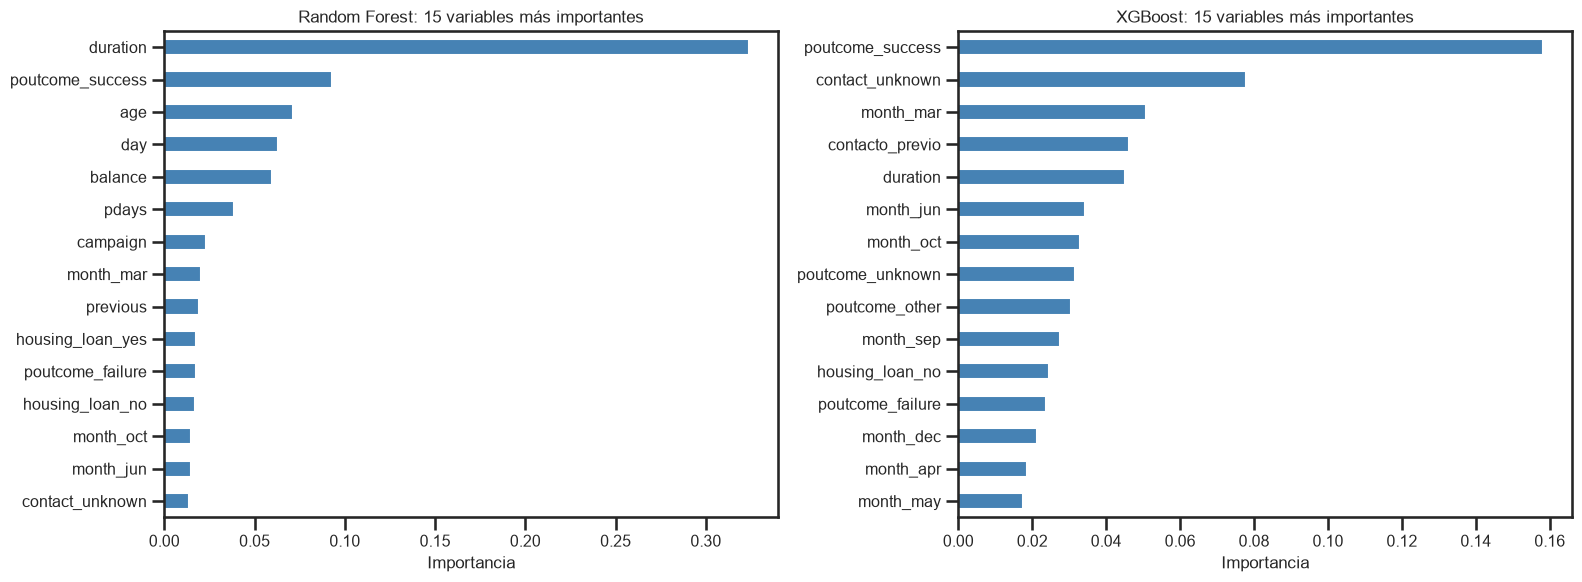

In [15]:
# importancia de variables del Random Forest y de XGBoost (como en la clase 06)
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
for ax, nombre in zip(axs, ['Random Forest', 'XGBoost']):
    modelo = busquedas[nombre].best_estimator_
    imp = pd.Series(modelo.named_steps['clf'].feature_importances_,
                    index=modelo.named_steps['pre'].get_feature_names_out()).sort_values(ascending=False)
    imp.index = imp.index.str.replace('num__', '').str.replace('cat__', '')
    imp.head(15)[::-1].plot.barh(ax=ax, color='steelblue')
    ax.set_title(f'{nombre}: 15 variables más importantes')
    ax.set_xlabel('Importancia')
plt.tight_layout()
guardar('ml_importancia')
plt.show()

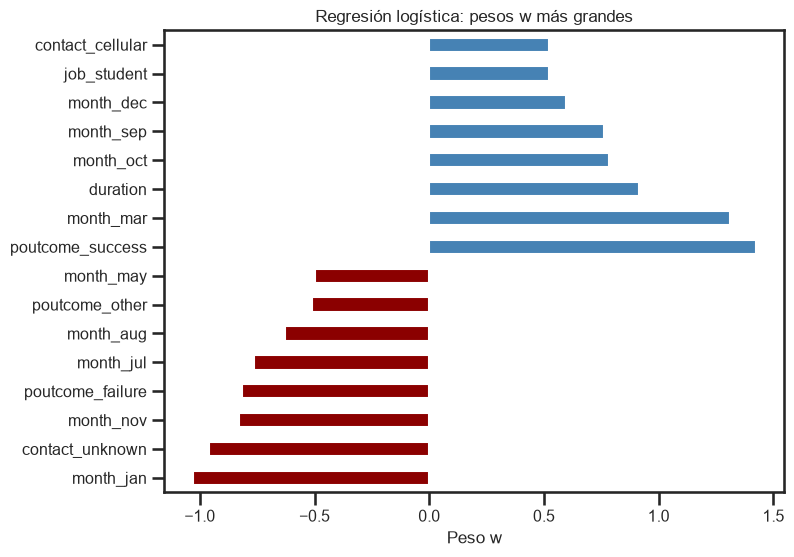

In [16]:
# pesos w de la regresión logística (las variables están estandarizadas, así que son comparables entre sí)
lr = busquedas['Regresión Logística'].best_estimator_
coef = pd.Series(lr.named_steps['clf'].coef_[0], index=lr.named_steps['pre'].get_feature_names_out())
coef.index = coef.index.str.replace('num__', '').str.replace('cat__', '')
top = pd.concat([coef.nsmallest(8), coef.nlargest(8)])
fig, ax = plt.subplots(figsize=(8, 6))
top.plot.barh(ax=ax, color=['darkred' if v < 0 else 'steelblue' for v in top])
ax.set_title('Regresión logística: pesos w más grandes')
ax.set_xlabel('Peso w')
plt.show()

# Umbral de decisión según los costos de la campaña (clase 05)
Como vimos en clase, el accuracy trata todos los errores por igual, pero en la vida real no cuestan lo mismo. Supuesto ilustrativo (a validar con el banco):
- Contactar a un cliente cuesta **c = 10 €** (tiempo del operador).
- Cada suscripción genera un beneficio de **b = 100 €**.

Para **un solo cliente** con probabilidad de suscribir $p$, conviene llamarlo si su beneficio esperado es positivo:
$$p \cdot b - c > 0 \quad\Longrightarrow\quad p > \frac{c}{b} = 0{,}10$$
El umbral óptimo es **0,10**, no 0,5, y sale directo de los costos.

In [17]:
c, b = 10, 100                                   # costo por llamada y beneficio por suscripción
umbral_costos = c / b                            # umbral teórico

def beneficio(y_true, llamar):
    # beneficio neto de la campaña: ganancia por suscripciones conseguidas - costo de todas las llamadas
    return b * ((llamar == 1) & (y_true == 1)).sum() - c * llamar.sum()

y_true = y_test.values
print('Llamar a TODOS:          ', beneficio(y_true, np.ones(len(y_true), dtype=int)), '€')
print('Llamar a NADIE:          ', beneficio(y_true, np.zeros(len(y_true), dtype=int)), '€')
print('Modelo (umbral 0.5):     ', beneficio(y_true, (p_mejor >= 0.5).astype(int)), '€')
print(f'Modelo (umbral {umbral_costos:.2f}):    ', beneficio(y_true, (p_mejor >= umbral_costos).astype(int)), '€')
llamar = (p_mejor >= umbral_costos).astype(int)
print(f'\nCon umbral {umbral_costos:.2f} se llama a {llamar.sum()} de {len(y_true)} clientes ({llamar.mean():.0%})')

Llamar a TODOS:           15370 €
Llamar a NADIE:           0 €
Modelo (umbral 0.5):      39260 €
Modelo (umbral 0.10):     68610 €

Con umbral 0.10 se llama a 2279 de 9043 clientes (25%)


,accuracy,sensibilidad,especificidad,auc_roc
umbral 0.5,0.907,0.439,0.969,0.919
umbral 0.10,0.833,0.864,0.829,0.919


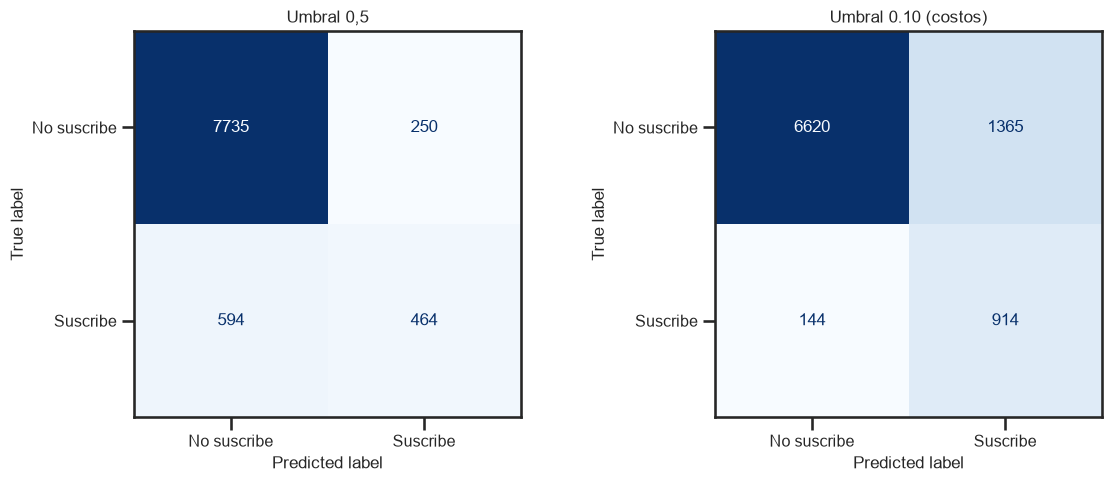

In [18]:
# comparamos métricas y matrices de confusión con ambos umbrales
display(pd.DataFrame({'umbral 0.5': metricas(y_test, p_mejor, 0.5),
                      f'umbral {umbral_costos:.2f}': metricas(y_test, p_mejor, umbral_costos)}).T.round(3))
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
matriz_confusion(y_test, p_mejor, 0.5, 'Umbral 0,5', ax=axs[0])
matriz_confusion(y_test, p_mejor, umbral_costos, f'Umbral {umbral_costos:.2f} (costos)', ax=axs[1])
plt.tight_layout()
guardar('ml_confusion_umbral')
plt.show()

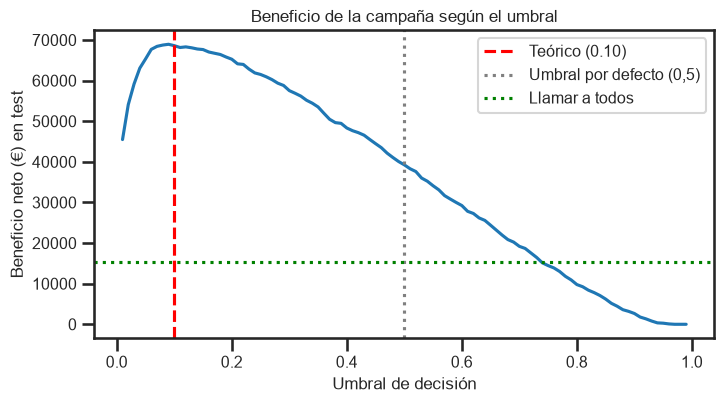

Umbral con máximo beneficio en el barrido: 0.09


In [19]:
# "confiemos pero verifiquemos": barremos todos los umbrales y vemos dónde está el máximo beneficio
umbrales = np.linspace(0.01, 0.99, 99)
benef = np.array([beneficio(y_true, (p_mejor >= u).astype(int)) for u in umbrales])
plt.figure(figsize=(8, 4))
plt.plot(umbrales, benef)
plt.axvline(umbral_costos, color='r', ls='--', label=f'Teórico ({umbral_costos:.2f})')
plt.axvline(0.5, color='gray', ls=':', label='Umbral por defecto (0,5)')
plt.axhline(beneficio(y_true, np.ones(len(y_true), dtype=int)), color='green', ls=':', label='Llamar a todos')
plt.xlabel('Umbral de decisión'); plt.ylabel('Beneficio neto (€) en test'); plt.legend()
plt.title('Beneficio de la campaña según el umbral')
guardar('ml_beneficio')
plt.show()
print(f'Umbral con máximo beneficio en el barrido: {umbrales[benef.argmax()]:.2f}')

Al bajar el umbral de 0,5 a 0,10 el **accuracy baja** pero la **sensibilidad sube** y el **beneficio de la campaña aumenta**: un modelo "peor" según el accuracy es mejor para el negocio. El máximo de la curva cae cerca del umbral teórico c/b. Esto ocurre porque las probabilidades del modelo son razonablemente buenas estimaciones de la probabilidad real de suscribir.

# Reducción de dimensionalidad: PCA (clase 09)
**Motivación.** Luego de crear las dummies, cada cliente queda descripto en un espacio de $d = 52$ dimensiones. Existe la hipótesis de que la variabilidad intrínseca de los datos vive en un **sub-espacio latente** $Z$ de dimensión $p < d$: algunas variables son redundantes (p. ej. `pdays`, `previous` y `contacto_previo` miden casi lo mismo) o ruidosas. Además, a mayor dimensión más parámetros debe aprender el modelo y KNN sufre la **maldición de la dimensionalidad**. Si el desempeño se mantiene (o mejora) con menos dimensiones, se sostiene la hipótesis de que muchas dimensiones originales eran ruido.

**Algoritmo de PCA** (transforma $X_{n \times d}$ en $Z_{n \times p}$):
1. Estandarizar / auto-escalar los datos (media 0, desvío 1) → ya lo hace el preprocesador.
2. Computar la matriz de covarianza $\Sigma$ de los datos.
3. Descomposición espectral de $\Sigma$ en **autovalores** $\lambda$ y **autovectores** $V$.
4. Ordenar los autovalores de mayor a menor (cada autovalor = variabilidad que explica su autovector).
5. Proyectar los datos sobre los $p$ autovectores de mayores autovalores → las **componentes principales**.

Las componentes son **combinaciones lineales** de las features originales y PCA es **no supervisado**: no usa la etiqueta `subscription`. Se ajusta solo con train (dentro del Pipeline) y se aplica a test.

Lo usamos para: 1) ver cuánta varianza capturan las componentes, 2) visualizar los clientes en 2D y 3) volver a entrenar los modelos sobre las componentes y comparar.

In [20]:
pre_pca = construir_preprocesador(num_cols, cat_cols).fit(X_train)    # ajustado solo con train
Xtr_p = pre_pca.transform(X_train)                                     # train preprocesado
nombres_feat = pd.Series(pre_pca.get_feature_names_out()).str.replace('num__', '').str.replace('cat__', '')
print('Dimensión original (luego de las dummies):', Xtr_p.shape[1])

pca_full = PCA(random_state=RANDOM_STATE).fit(Xtr_p)                   # todas las componentes
var_acum = np.cumsum(pca_full.explained_variance_ratio_)               # varianza explicada acumulada
k80, k90, k95 = [int(np.argmax(var_acum >= t) + 1) for t in (0.80, 0.90, 0.95)]
print(f'Componentes para 80% de varianza: {k80} | 90%: {k90} | 95%: {k95}')

Dimensión original (luego de las dummies): 52
Componentes para 80% de varianza: 11 | 90%: 17 | 95%: 23


In [21]:
# verificación "a mano" del algoritmo de PCA visto en clase:
# matriz de covarianza -> autovalores y autovectores -> ordenar de mayor a menor
sigma = np.cov(Xtr_p, rowvar=False)                    # matriz de covarianza (d x d)
autovalores, autovectores = np.linalg.eigh(sigma)      # descomposición espectral (matriz simétrica)
orden = np.argsort(autovalores)[::-1]                  # orden de mayor a menor
autovalores, autovectores = autovalores[orden], autovectores[:, orden]
print('Primeros 5 autovalores (numpy):  ', autovalores[:5].round(4))
print('Primeros 5 autovalores (sklearn):', pca_full.explained_variance_[:5].round(4))
print('¿Coinciden los autovectores (salvo signo)?',
      np.allclose(np.abs(autovectores[:, :5]), np.abs(pca_full.components_[:5].T), atol=1e-6))

Primeros 5 autovalores (numpy):   [2.5223 1.1817 1.1676 0.9856 0.9448]
Primeros 5 autovalores (sklearn): [2.5223 1.1817 1.1676 0.9856 0.9448]
¿Coinciden los autovectores (salvo signo)? True


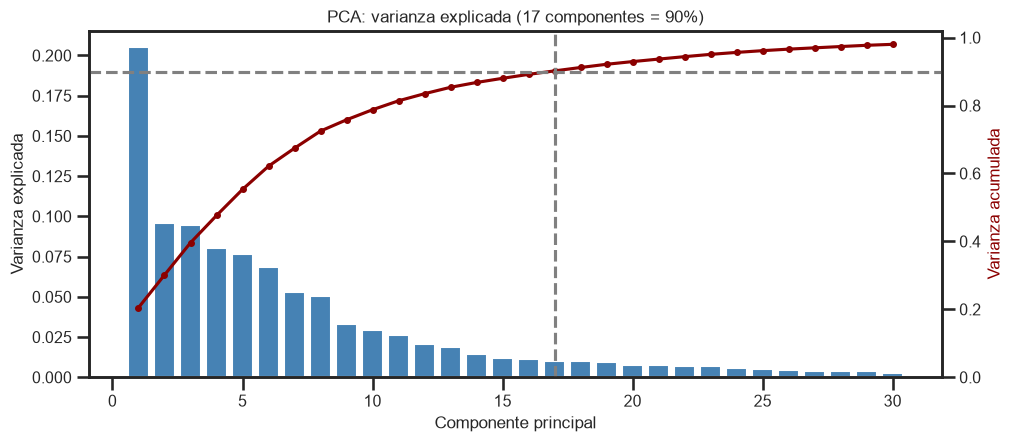

In [22]:
n_show = 30
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(range(1, n_show + 1), pca_full.explained_variance_ratio_[:n_show], color='steelblue', label='Varianza explicada')
ax1.set_xlabel('Componente principal'); ax1.set_ylabel('Varianza explicada')
ax2 = ax1.twinx()
ax2.plot(range(1, n_show + 1), var_acum[:n_show], color='darkred', marker='o', ms=4, label='Acumulada')
ax2.axhline(0.90, color='gray', ls='--'); ax2.axvline(k90, color='gray', ls='--')
ax2.set_ylabel('Varianza acumulada', color='darkred'); ax2.set_ylim(0, 1.02)
ax1.set_title(f'PCA: varianza explicada ({k90} componentes = 90%)')
guardar('ml_pca_varianza')
plt.show()

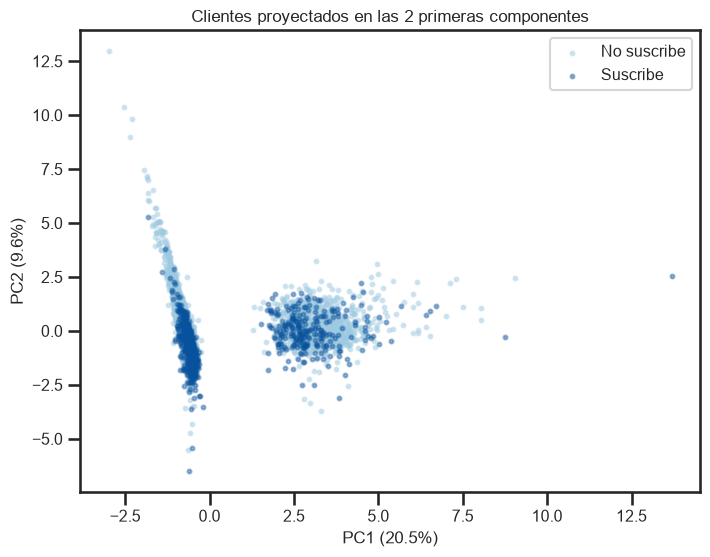

In [23]:
# proyección de los clientes de train sobre las dos primeras componentes
Z = pca_full.transform(Xtr_p)[:, :2]
idx = np.random.RandomState(0).choice(len(Z), 6000, replace=False)     # muestra para que se vea mejor
plt.figure(figsize=(8, 6))
for clase, color, lab in [(0, '#9ecae1', 'No suscribe'), (1, '#08519c', 'Suscribe')]:
    m = (y_train.values[idx] == clase)
    plt.scatter(Z[idx][m, 0], Z[idx][m, 1], s=8, alpha=0.4, c=color, label=lab)
plt.xlabel(f'PC1 ({pca_full.explained_variance_ratio_[0]:.1%})')
plt.ylabel(f'PC2 ({pca_full.explained_variance_ratio_[1]:.1%})')
plt.legend(); plt.title('Clientes proyectados en las 2 primeras componentes')
guardar('ml_pca_scatter')
plt.show()

In [24]:
# qué variables originales pesan más en las 2 primeras componentes (componentes de los autovectores)
loadings = pd.DataFrame(pca_full.components_[:2].T, index=nombres_feat, columns=['PC1', 'PC2'])
pd.concat([loadings['PC1'].abs().nlargest(6).rename('|PC1|'),
           loadings['PC2'].abs().nlargest(6).rename('|PC2|')], axis=1).round(3)

,|PC1|,|PC2|
contacto_previo,0.599,0.067
pdays,0.580,NaN
previous,0.428,0.118
poutcome_unknown,0.231,NaN
poutcome_failure,0.140,NaN
campaign,0.111,0.653
day,NaN,0.608
duration,NaN,0.393
age,NaN,0.081


Las dos primeras componentes explican poca varianza y las clases se superponen mucho: el problema **no es linealmente separable en 2D**. PC1 está dominada por `pdays/previous/contacto_previo/poutcome` (historia de contactos previos) y PC2 por `campaign`, `day` y `duration`.

## ¿Cuántas componentes usar? → hiper-parámetro del Pipeline (clase 07)
Como el PCA está dentro del Pipeline, la **cantidad de componentes** (y si se aplica o no PCA) es un hiper-parámetro más que se elige con `GridSearchCV`. Lo hacemos con la regresión logística (rápida de entrenar):

Mejor configuración: {'pca': 'passthrough'}


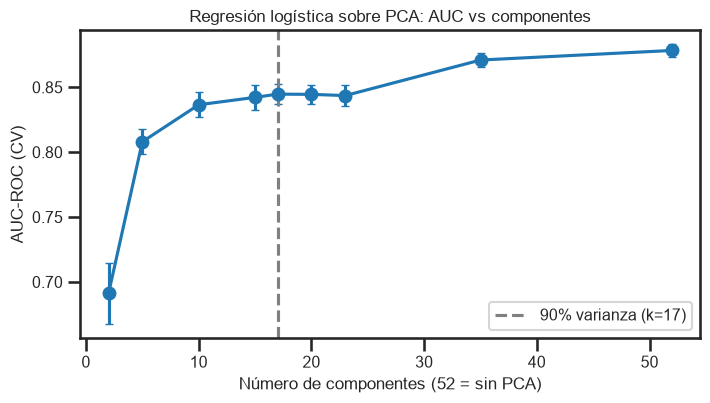

,n_componentes,auc_cv,std
0,2,0.6911,0.0237
1,5,0.8080,0.0098
2,10,0.8365,0.0095
3,15,0.8422,0.0095
4,17,0.8447,0.0077
5,20,0.8445,0.0074
6,23,0.8436,0.0078
7,35,0.8710,0.0057
8,52,0.8784,0.0047


In [25]:
lr_params = {k.replace('clf__', ''): v for k, v in busquedas['Regresión Logística'].best_params_.items()}
n_comp_lista = sorted(set([2, 5, 10, 15, 20, k90, k95, 35]))
pipe = Pipeline([('pre', construir_preprocesador(num_cols, cat_cols)),
                 ('pca', PCA(random_state=RANDOM_STATE)),
                 ('clf', LogisticRegression(max_iter=2000, **lr_params))])
grilla_pca = [{'pca__n_components': n_comp_lista},       # distintas cantidades de componentes
              {'pca': ['passthrough']}]                    # sin PCA (las 52 features originales)
gs_pca = GridSearchCV(pipe, grilla_pca, cv=CV, scoring='roc_auc', n_jobs=-1).fit(X_train, y_train)
res = pd.DataFrame(gs_pca.cv_results_)
auc_vs_k = pd.DataFrame({'n_componentes': res['param_pca__n_components'].fillna(Xtr_p.shape[1]).astype(int),
                         'auc_cv': res['mean_test_score'], 'std': res['std_test_score']}).sort_values('n_componentes')
print('Mejor configuración:', gs_pca.best_params_)
plt.figure(figsize=(8, 4))
plt.errorbar(auc_vs_k.n_componentes, auc_vs_k.auc_cv, yerr=auc_vs_k['std'], marker='o', capsize=3)
plt.axvline(k90, color='gray', ls='--', label=f'90% varianza (k={k90})')
plt.xlabel('Número de componentes (52 = sin PCA)'); plt.ylabel('AUC-ROC (CV)'); plt.legend()
plt.title('Regresión logística sobre PCA: AUC vs componentes')
guardar('ml_pca_auc_vs_k')
plt.show()
auc_vs_k.round(4)

## Re-entrenamiento de todos los modelos con PCA (componentes que explican el 90% de la varianza)
Se usan los mejores hiper-parámetros encontrados antes para cada modelo y se agrega el paso `PCA` al pipeline.

In [26]:
probas_pca, res_pca = {}, []
for nombre, gs in busquedas.items():
    clf = gs.best_estimator_.named_steps['clf']                     # mismo modelo y mismos hiper-parámetros
    pipe = Pipeline([('pre', construir_preprocesador(num_cols, cat_cols)),
                     ('pca', PCA(n_components=k90, random_state=RANDOM_STATE)),
                     ('clf', clf.__class__(**clf.get_params()))])
    t0 = time.time()
    auc_cv = cross_val_score(pipe, X_train, y_train, cv=CV, scoring='roc_auc', n_jobs=-1).mean()
    pipe.fit(X_train, y_train)
    probas_pca[nombre] = pipe.predict_proba(X_test)[:, 1]
    res_pca.append({'modelo': nombre, 'escenario': f'PCA ({k90} comp.)', 'auc_cv': auc_cv, **metricas(y_test, probas_pca[nombre])})
    print(f'{nombre:22s} AUC CV = {auc_cv:.4f}  AUC test = {res_pca[-1]["auc_roc"]:.4f}  ({time.time() - t0:.0f} s)')
res_pca = pd.DataFrame(res_pca)

Regresión Logística    AUC CV = 0.8447  AUC test = 0.8513  (3 s)
KNN                    AUC CV = 0.8535  AUC test = 0.8538  (6 s)
Árbol de Decisión      AUC CV = 0.8204  AUC test = 0.8211  (6 s)
Random Forest          AUC CV = 0.8683  AUC test = 0.8692  (140 s)
XGBoost                AUC CV = 0.8769  AUC test = 0.8772  (16 s)
Red Neuronal (MLP)     AUC CV = 0.8778  AUC test = 0.8805  (62 s)


,modelo,escenario,auc_cv,auc_roc,accuracy,sensibilidad,especificidad
5,KNN,Original,0.876,0.876,0.896,0.214,0.987
1,KNN,PCA (17 comp.),0.853,0.854,0.891,0.161,0.988
1,Random Forest,Original,0.907,0.912,0.901,0.304,0.980
3,Random Forest,PCA (17 comp.),0.868,0.869,0.892,0.233,0.979
2,Red Neuronal (MLP),Original,0.899,0.901,0.903,0.435,0.965
5,Red Neuronal (MLP),PCA (17 comp.),0.878,0.880,0.892,0.307,0.970
4,Regresión Logística,Original,0.878,0.883,0.900,0.304,0.979
0,Regresión Logística,PCA (17 comp.),0.845,0.851,0.892,0.190,0.985
0,XGBoost,Original,0.918,0.919,0.907,0.439,0.969
4,XGBoost,PCA (17 comp.),0.877,0.877,0.893,0.299,0.972


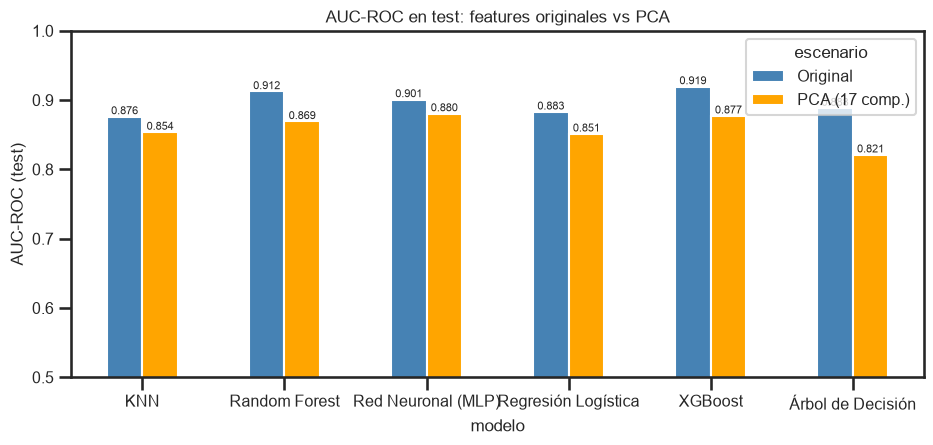

In [27]:
# comparación original vs PCA en test
orig = res_test.merge(cv_res[['modelo', 'auc_cv_media']].rename(columns={'auc_cv_media': 'auc_cv'}), on='modelo')
columnas = ['modelo', 'escenario', 'auc_cv', 'auc_roc', 'accuracy', 'sensibilidad', 'especificidad']
comparacion = pd.concat([orig, res_pca])[columnas]
display(comparacion.sort_values(['modelo', 'escenario']).round(3))

pivot = comparacion.pivot(index='modelo', columns='escenario', values='auc_roc')
ax = pivot.plot.bar(figsize=(11, 4.5), rot=0, color=['steelblue', 'orange'])
ax.set_ylim(0.5, 1); ax.set_ylabel('AUC-ROC (test)')
ax.set_title('AUC-ROC en test: features originales vs PCA')
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.3f', fontsize=8)
guardar('ml_comparacion_pca')
plt.show()

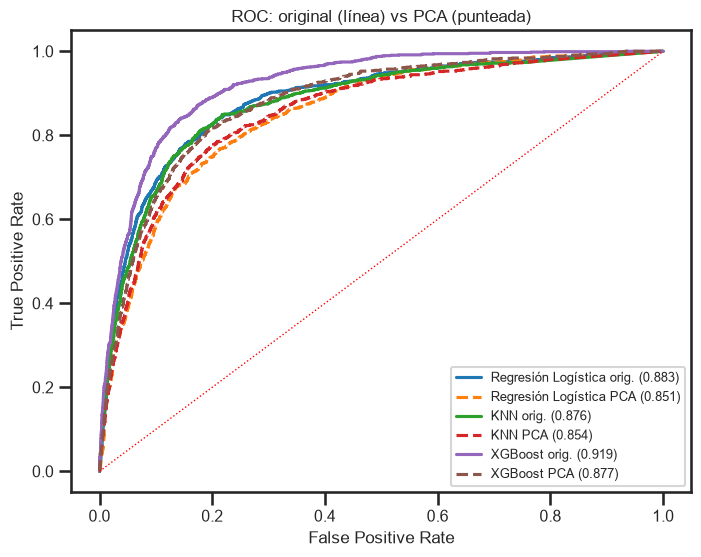

In [28]:
fig, ax = plt.subplots(figsize=(8, 6))
for nombre in ['Regresión Logística', 'KNN', mejor_nombre]:
    for p, ls, esc in [(probas[nombre], '-', 'orig.'), (probas_pca[nombre], '--', 'PCA')]:
        fpr, tpr, _ = roc_curve(y_test, p)
        ax.plot(fpr, tpr, ls=ls, label=f'{nombre} {esc} ({roc_auc_score(y_test, p):.3f})')
ax.plot([0, 1], [0, 1], 'r:', lw=1)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate'); ax.legend(fontsize=9)
ax.set_title('ROC: original (línea) vs PCA (punteada)')
plt.show()

# Escenario realista: modelos sin `duration`
`duration` solo se conoce **después** de la llamada, por lo que no puede usarse para decidir a quién llamar: es un caso de *data leakage* conceptual (clase 07). Re-entrenamos los modelos con mejor desempeño (con los mismos hiper-parámetros) sin esa variable, con y sin PCA.

In [29]:
num_sin_dur = [c_ for c_ in num_cols if c_ != 'duration']
X_train_sd, X_test_sd = X_train.drop(columns='duration'), X_test.drop(columns='duration')
res_sin_dur, probas_sd = [], {}
for nombre in ['Regresión Logística', 'Random Forest', 'XGBoost', 'Red Neuronal (MLP)']:
    clf = busquedas[nombre].best_estimator_.named_steps['clf']
    for usar_pca in [False, True]:
        pasos = [('pre', construir_preprocesador(num_sin_dur, cat_cols))]
        if usar_pca:
            pasos.append(('pca', PCA(n_components=0.90, random_state=RANDOM_STATE)))   # 90% de varianza
        pasos.append(('clf', clf.__class__(**clf.get_params())))
        pipe = Pipeline(pasos)
        auc_cv = cross_val_score(pipe, X_train_sd, y_train, cv=CV, scoring='roc_auc', n_jobs=-1).mean()
        pipe.fit(X_train_sd, y_train)
        p = pipe.predict_proba(X_test_sd)[:, 1]
        esc = 'Sin duration' + (' + PCA' if usar_pca else '')
        probas_sd[(nombre, esc)] = p
        res_sin_dur.append({'modelo': nombre, 'escenario': esc, 'auc_cv': auc_cv, **metricas(y_test, p)})
res_sin_dur = pd.DataFrame(res_sin_dur)
res_sin_dur[columnas].round(3)

,modelo,escenario,auc_cv,auc_roc,accuracy,sensibilidad,especificidad
0,Regresión Logística,Sin duration,0.760,0.770,0.892,0.167,0.988
1,Regresión Logística,Sin duration + PCA,0.716,0.728,0.883,0.005,1.000
2,Random Forest,Sin duration,0.790,0.803,0.895,0.193,0.988
3,Random Forest,Sin duration + PCA,0.746,0.756,0.884,0.056,0.994
4,XGBoost,Sin duration,0.796,0.807,0.895,0.249,0.981
5,XGBoost,Sin duration + PCA,0.753,0.762,0.884,0.098,0.988
6,Red Neuronal (MLP),Sin duration,0.772,0.786,0.894,0.256,0.979
7,Red Neuronal (MLP),Sin duration + PCA,0.751,0.760,0.882,0.075,0.989


In [30]:
# umbral de costos aplicado al mejor modelo sin duration
p_sd = probas_sd[(mejor_nombre, 'Sin duration')]
llamar_sd = (p_sd >= umbral_costos).astype(int)
print(f'{mejor_nombre} sin duration, umbral c/b = {umbral_costos:.2f}')
print(pd.Series(metricas(y_test, p_sd, umbral_costos)).round(3))
print('Beneficio neto en test:', beneficio(y_true, llamar_sd), '€  | llamar a todos:',
      beneficio(y_true, np.ones(len(y_true), dtype=int)), '€')
print(f'Llamadas: {llamar_sd.sum()} de {len(y_true)} ({llamar_sd.mean():.0%})')

XGBoost sin duration, umbral c/b = 0.10
accuracy         0.771
sensibilidad     0.698
especificidad    0.781
auc_roc          0.807
dtype: float64
Beneficio neto en test: 48940 €  | llamar a todos: 15370 €
Llamadas: 2486 de 9043 (27%)


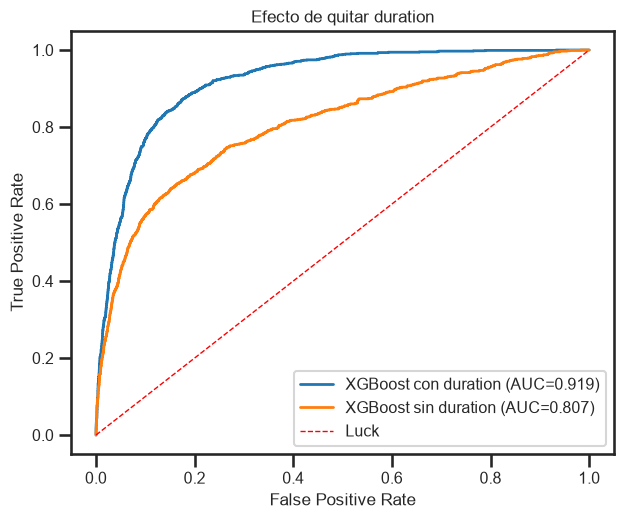

In [31]:
# curvas ROC del mejor modelo con y sin duration
plt.figure(figsize=(7, 5.5))
for etiqueta, p in [(f'{mejor_nombre} con duration', p_mejor), (f'{mejor_nombre} sin duration', p_sd)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, lw=2, label=f'{etiqueta} (AUC={roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', lw=1, color='r', label='Luck')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate'); plt.legend(loc='lower right')
plt.title('Efecto de quitar duration')
guardar('ml_roc_sin_duration')
plt.show()

# Resumen de resultados

In [32]:
final = pd.concat([comparacion, res_sin_dur[columnas]])
final = final.sort_values(['escenario', 'auc_roc'], ascending=[True, False]).reset_index(drop=True)
final.to_csv('resultados/resultados_modelos.csv', index=False)
final.round(3)

,modelo,escenario,auc_cv,auc_roc,accuracy,sensibilidad,especificidad
0,XGBoost,Original,0.918,0.919,0.907,0.439,0.969
1,Random Forest,Original,0.907,0.912,0.901,0.304,0.980
2,Red Neuronal (MLP),Original,0.899,0.901,0.903,0.435,0.965
3,Árbol de Decisión,Original,0.879,0.888,0.900,0.408,0.965
4,Regresión Logística,Original,0.878,0.883,0.900,0.304,0.979
5,KNN,Original,0.876,0.876,0.896,0.214,0.987
6,Red Neuronal (MLP),PCA (17 comp.),0.878,0.880,0.892,0.307,0.970
7,XGBoost,PCA (17 comp.),0.877,0.877,0.893,0.299,0.972
8,Random Forest,PCA (17 comp.),0.868,0.869,0.892,0.233,0.979
9,KNN,PCA (17 comp.),0.853,0.854,0.891,0.161,0.988


# Conclusiones
- **El accuracy no es una métrica adecuada con clases desbalanceadas:** el modelo de referencia que nunca predice suscripción logra 88,3% de accuracy, con sensibilidad 0 y AUC 0,5 ("tirar una moneda"). Los modelos se seleccionaron por **AUC-ROC en validación cruzada** y se evaluaron también con sensibilidad y especificidad.
- **Comparación de modelos (test, variables originales):** el mejor fue el ensamble por **boosting (XGBoost, AUC 0,919)**, seguido por el ensamble por **bagging (Random Forest, 0,912)** y la **red neuronal MLP (0,901)**. Luego vienen el árbol de decisión (0,888), la regresión logística (0,883) y KNN (0,876). Esto coincide con la teoría: los ensambles mejoran a un árbol individual, y los modelos no lineales captan relaciones como la de la edad (forma de U), que un modelo lineal no puede representar.
- **Generalización:** los AUC en test coinciden con los de validación cruzada (diferencias ≤ 0,01), así que la búsqueda de hiper-parámetros no sobre-ajustó. La curva de aprendizaje de XGBoost muestra una brecha moderada entre train (0,96) y validación (0,92) que se achica al agregar muestras. Hay algo de **varianza**, pero no un problema de **sesgo**.
- **Umbral de decisión (clase 05):** con el umbral por defecto de 0,5, XGBoost detecta solo el 44% de los suscriptores (sensibilidad 0,44, especificidad 0,97). Suponiendo un costo de 10 € por llamada y un beneficio de 100 € por suscripción, el umbral óptimo es c/b = 0,10. Con ese umbral la sensibilidad sube a 0,86 (con especificidad 0,83) y el beneficio de la campaña pasa de 39.260 € a **68.610 €**, contra 15.370 € de llamar a todos, contactando solo al 25% de los clientes. El accuracy baja (de 0,91 a 0,83), pero el resultado para el negocio es mucho mejor. El barrido de umbrales confirma que el máximo está en 0,09, prácticamente el valor teórico.
- **Reducción de dimensionalidad (PCA):** la verificación "a mano" (matriz de covarianza → autovalores y autovectores) coincide con scikit-learn. Con 17 componentes (de 52 features) se explica el 90% de la varianza, pero al re-entrenar el AUC baja en todos los modelos (entre −0,02 y −0,07). Usando la cantidad de componentes como hiper-parámetro del Pipeline, el GridSearch elige **no aplicar PCA**. Por lo tanto **no se sostiene la hipótesis** de que las dimensiones descartadas sean ruido. PCA es **no supervisado**: retiene las direcciones de mayor varianza, no las que mejor separan a los que suscriben de los que no, y algunas direcciones de poca varianza (p. ej. `poutcome = success` o meses con pocos contactos) son muy informativas. Además, con 36.000 muestras para 52 dimensiones no estamos en una situación de maldición de la dimensionalidad. En este problema la utilidad de PCA es la **visualización** (en el plano PC1–PC2 las clases se superponen) y la reducción de cómputo.
- **`duration` y data leakage:** es la variable más importante, pero solo se conoce **después** de la llamada. Sin ella, el AUC realista de XGBoost es **0,807** (Random Forest 0,803, MLP 0,786, regresión logística 0,770). Aun así el modelo es útil para decidir a quién llamar: con el umbral de costos se contacta al 27% de los clientes, se detecta el 70% de los suscriptores y se obtienen **48.940 € vs 15.370 €** de llamar a todos.
- **Recomendaciones al banco:** priorizar clientes con éxito en campañas previas, estudiantes y jubilados, contactados por celular y sin préstamos; no insistir más de 3–4 veces en la misma campaña; reducir el volumen de llamadas en mayo.

# Referencias
1. James, G., Witten, D., Hastie, T., Tibshirani, R. & Taylor, J. (2023). *An Introduction to Statistical Learning with Applications in Python*. Springer.
2. Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*. Springer.
3. Murphy, K. P. (2022). *Probabilistic Machine Learning: An Introduction*. MIT Press.
4. Goodfellow, I., Bengio, Y. & Courville, A. (2016). *Deep Learning*. MIT Press.
5. Géron, A. (2022). *Hands-On Machine Learning with Scikit-Learn, Keras & TensorFlow* (3.ª ed.). O'Reilly.
6. Moro, S., Cortez, P. & Rita, P. (2014). A data-driven approach to predict the success of bank telemarketing. *Decision Support Systems*, 62, 22–31.